In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage.io
import skimage.measure
from IPython.display import display, Markdown

In [2]:
# Introduction
display(Markdown("""
# 📌 Coordinate Transformation Notebook

This notebook helps users transform coordinates from a global reference frame to a new coordinate system, generated using a plugin.
We will cover two use cases:

1. **Transforming manually provided points** into the new reference frame.
2. **Transforming cell centroids extracted from a segmentation mask** into the new reference frame.

Each section will guide you through the process, from loading data to saving transformed coordinates.
"""))


# 📌 Coordinate Transformation Notebook

This notebook helps users transform coordinates from a global reference frame to a new coordinate system, generated using a plugin.
We will cover two use cases:

1. **Transforming manually provided points** into the new reference frame.
2. **Transforming cell centroids extracted from a segmentation mask** into the new reference frame.

Each section will guide you through the process, from loading data to saving transformed coordinates.


In [34]:
# Function to load the coordinate system from CSV
def load_coordinate_system(csv_path):
    """
    Loads the new coordinate system's origin and basis vectors from a CSV file.
    The CSV should have three rows: the first for the origin, and the next two for the basis vectors.
    """
    df = pd.read_csv(csv_path, header=None)
    origin = list(map(float, df[0][1].strip("[]").split()))
    u, v, w = list(map(float, df[1][1].strip("[]").split())), list(map(float, df[2][1].strip("[]").split())),                       list(map(float, df[3][1].strip("[]").split()))

    return origin, u, v, w

# Function to transform points to the new coordinate system
def transform_points(points, origin, u, v, w):
    """
    Transforms a set of points into the new coordinate system.
    """
    transformation_matrix = np.column_stack((u, v, w))
    transformed_points = np.linalg.solve(transformation_matrix, (points - origin).T).T
    return transformed_points


In [35]:
# Load the CSV with coordinate system information
csv_path = "coordinate_system.csv"  # Replace with the actual file path
# Replace with the actual file path
origin, u, v, w = load_coordinate_system(csv_path)

In [36]:

# Section 1: Transforming user-provided points
display(Markdown("""
## 🟢 Section 1: Transforming User-Provided Points

If you have specific points whose coordinates you want to express in the new reference frame, you can input them below.
The transformed coordinates will be saved as a new CSV file.
"""))


## 🟢 Section 1: Transforming User-Provided Points

If you have specific points whose coordinates you want to express in the new reference frame, you can input them below.
The transformed coordinates will be saved as a new CSV file.


In [56]:

# Define the points (user must manually input their points)
points = np.array([
    [5.0, 10.0, 15.0],
    [8.0, 12.0, 20.0],
    [10.0, 15.0, 25.0]
])  # Replace with user points

# Transform the points
transformed_points = transform_points(points, origin, u, v, w)

# Save the transformed points
output_csv = "transformed_points.csv"
pd.DataFrame(transformed_points, columns=["X_new", "Y_new", "Z_new"]).to_csv(output_csv, index=False)
display(Markdown(f"✅ **Transformed points saved to `{output_csv}`**"))

✅ **Transformed points saved to `transformed_points.csv`**

In [51]:

# Section 2: Transforming Cell Centroids from a Segmentation Mask
display(Markdown("""
## 🔵 Section 2: Transforming Cell Centroids from a Segmentation Mask

If you have a segmentation mask (image where different regions represent detected cells), this section will:
1. Extract the centroids of each detected region using `regionprops`.
2. Transform those centroids into the new reference frame.
3. Save the transformed coordinates into a new CSV file.
"""))


## 🔵 Section 2: Transforming Cell Centroids from a Segmentation Mask

If you have a segmentation mask (image where different regions represent detected cells), this section will:
1. Extract the centroids of each detected region using `regionprops`.
2. Transform those centroids into the new reference frame.
3. Save the transformed coordinates into a new CSV file.


In [52]:
# Load the segmentation mask
mask_path = "/path/mask"  # Replace with the actual file path
mask = skimage.io.imread(mask_path)

# Extract cell centroids using regionprops
props = skimage.measure.regionprops(mask)
centroids = np.array([prop.centroid for prop in props])

# Transform the centroids into the new coordinate system
transformed_centroids = transform_points(centroids, origin, u, v, w)

# Save the transformed centroids
output_csv_centroids = "transformed_centroids.csv"
pd.DataFrame(transformed_centroids, columns=["X_new", "Y_new", "Z_new"]).to_csv(output_csv_centroids, index=False)
display(Markdown(f"✅ **Transformed centroids saved to `{output_csv_centroids}`**"))

✅ **Transformed centroids saved to `transformed_centroids.csv`**


### 📊 Visualization

Below, you will see a 3D plot comparing the original and transformed coordinates.


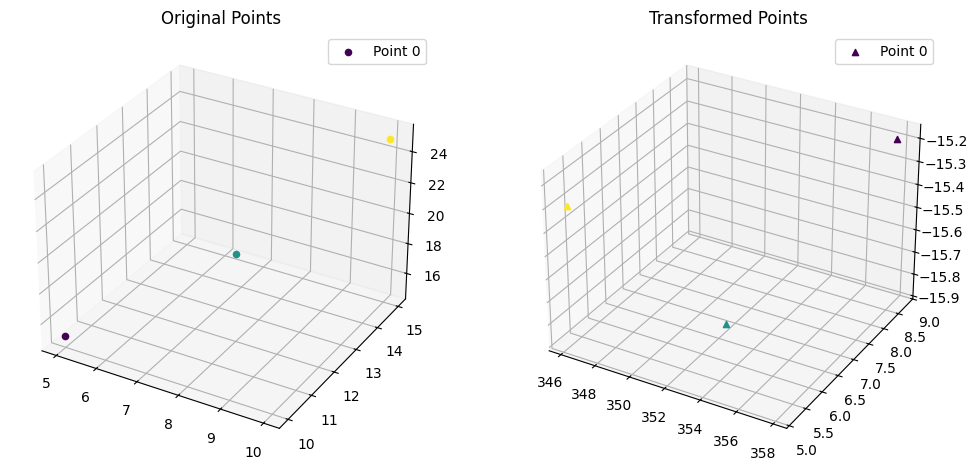


## ✅ Notebook Completed

You have successfully transformed your points and cell centroids into the new reference frame!
You can now use these transformed coordinates for further analysis or visualization.


In [58]:
# Affichage du titre de la visualisation
display(Markdown("""
### 📊 Visualization

Below, you will see a 3D plot comparing the original and transformed coordinates.
"""))

# Création de la figure
fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122, projection='3d')

num_points = centroids.shape[0]

# Attribution des couleurs uniques pour chaque point
colors = plt.cm.viridis(np.linspace(0, 1, num_points))

# Tracé des points originaux
for i in range(num_points):
    ax1.scatter(centroids[i, 0], centroids[i, 1], centroids[i, 2], c=[colors[i]], marker='o', label=f'Point {i}' if i == 0 else "")
ax1.set_title("Original Points")
ax1.legend()

# Tracé des points transformés avec la même couleur
for i in range(num_points):
    ax2.scatter(transformed_centroids[i, 0], transformed_centroids[i, 1], transformed_centroids[i, 2], c=[colors[i]], marker='^', label=f'Point {i}' if i == 0 else "")
ax2.set_title("Transformed Points")
ax2.legend()

# Affichage du graphique
plt.show()

# Message de fin
display(Markdown("""
## ✅ Notebook Completed

You have successfully transformed your points and cell centroids into the new reference frame!
You can now use these transformed coordinates for further analysis or visualization.
"""))